
# M8230 – Cvičení 5: Určité součty v aplikaci

V první části si na jednoduchých modelových datech ukážeme dva vyřešené příklady:

1. **incidence a kumulativní počet případů,**
2. **incidence a prevalence při pevné délce aktivity.**

Na závěr použijete stejné myšlenky samostatně na skutečných datech COVID-19 z Ministerstva zdravotnictví ČR.

Cílem je propojit **určité součty, kumulaci a diference** s časovými daty.


In [1]:
library(ggplot2)

# Větší rozměry grafů v notebooku
options(
  repr.plot.width = 11,
  repr.plot.height = 5.5,
  repr.plot.res = 100
)



## 1. Vyřešený příklad: incidence a kumulativní počet případů

Nechť $i(t)$ označuje denní incidenci, tedy počet nových případů mezi dny $t$ a $t+1$.

Kumulativní počet případů $C(t)$ splňuje

$$
C(t+1)=C(t)+i(t),
$$

tedy

$$
\Delta C(t)=i(t).
$$

Opačně lze kumulativní počet získat sumací incidence:

$$
C(t)=C(0)+\sum_{s=0}^{t-1}i(s).
$$

Použijeme jednoduchá modelová data za 30 dní.


In [2]:
# Zjednodušená denní incidence za 30 dní
i <- c(
  2, 3, 4, 6, 8, 11, 15, 18, 20, 19,
  17, 14, 11, 9, 7, 6, 5, 4, 4, 3,
  3, 2, 2, 2, 1, 1, 1, 1, 0, 0
)

days <- 0:(length(i) - 1)

# Počáteční kumulativní počet
C0 <- 0

# C(t) má o jednu hodnotu více než i(t):
# C(0), C(1), ..., C(30)
C <- c(C0, C0 + cumsum(i))

cat("Incidence i(t):\n")
print(i)

cat("\nKumulativní počet C(t):\n")
print(C)


Incidence i(t):
 [1]  2  3  4  6  8 11 15 18 20 19 17 14 11  9  7  6  5  4  4  3  3  2  2  2  1
[26]  1  1  1  0  0

Kumulativní počet C(t):
 [1]   0   2   5   9  15  23  34  49  67  87 106 123 137 148 157 164 170 175 179
[20] 183 186 189 191 193 195 196 197 198 199 199 199



Funkce `cumsum(i)` vytváří postupné částečné součty

$$
i(0),\quad i(0)+i(1),\quad i(0)+i(1)+i(2),\ldots
$$

a právě proto numericky realizuje sumaci, která vede od denních přírůstků ke kumulativnímu počtu.


In [3]:
# Ověření vztahu Delta C(t) = i(t)
Delta_C <- diff(C)

cat("Delta C(t):\n")
print(Delta_C)

cat("\nPlatí Delta C(t) = i(t)?\n")
print(all(Delta_C == i))


Delta C(t):
 [1]  2  3  4  6  8 11 15 18 20 19 17 14 11  9  7  6  5  4  4  3  3  2  2  2  1
[26]  1  1  1  0  0

Platí Delta C(t) = i(t)?
[1] TRUE


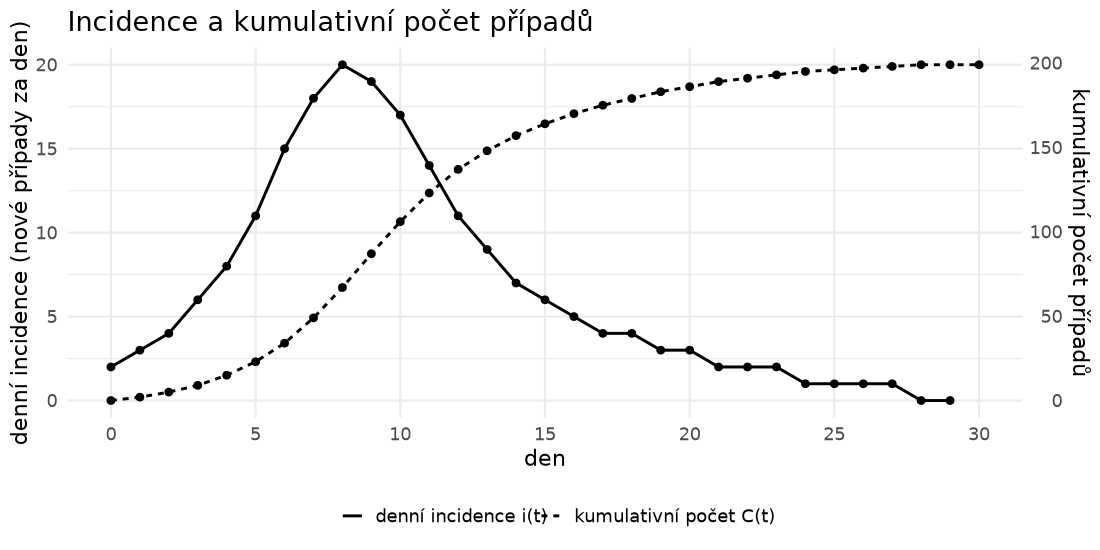

In [4]:
# Incidence a kumulativní počet mají odlišné měřítko.
# Pro společné zobrazení proto použijeme dvě osy y.
scale_factor <- max(C) / max(i)

plot_data <- rbind(
  data.frame(
    t = days,
    value = i,
    rada = "denní incidence i(t)"
  ),
  data.frame(
    t = 0:length(i),
    value = C / scale_factor,
    rada = "kumulativní počet C(t)"
  )
)

ggplot(plot_data, aes(x = t, y = value, linetype = rada)) +
  geom_line(linewidth = 1) +
  geom_point(size = 2) +
  scale_x_continuous(
    breaks = seq(0, length(i), by = 5)
  ) +
  scale_y_continuous(
    name = "denní incidence (nové případy za den)",
    sec.axis = sec_axis(
      ~ . * scale_factor,
      name = "kumulativní počet případů"
    )
  ) +
  labs(
    x = "den",
    title = "Incidence a kumulativní počet případů",
    linetype = NULL
  ) +
  theme_minimal(base_size = 16) +
  theme(
    legend.position = "bottom",
    panel.grid.minor.x = element_blank()
  )



### Co z příkladu plyne?

- Incidence $i(t)$ představuje **denní přírůstek** kumulativního počtu.
- Kumulativní počet získáme **sumací** incidence.
- Naopak incidenci získáme jako **první diferenci** kumulativního počtu:

$$
\boxed{\Delta C(t)=i(t)}.
$$

I když incidence po dosažení maxima začne klesat, kumulativní počet stále roste, dokud je incidence kladná.



## 2. Vyřešený příklad: prevalence při pevné délce aktivity

Navážeme na modelovou úlohu, ve které předpokládáme, že každý nový případ zůstává aktivní přesně $L$ časových kroků.

V původním zadání je $P(t)$ označeno jako **počet aktivních případů**.  
V tomto notebooku budeme tuto veličinu interpretovat jako **modelovou prevalenci**, tedy počet případů, které jsou v čase $t$ aktivní.

Předpokládejme tedy, že každý nový případ zůstává aktivní přesně $L$ dní. Potom je v čase $t$ aktivní právě ten případ, který vznikl během posledních $L$ dní.

Modelová prevalence je proto

$$
P(t)=\sum_{s=t-L}^{t-1}i(s),
$$

přičemž před začátkem sledování bereme incidenci rovnou nule.

Protože $C(t)$ je kumulativní součet incidence, můžeme stejnou veličinu zapsat také jako

$$
P(t)=C(t)-C(t-L).
$$

Použijeme $L=14$.


In [5]:
L <- 14
T <- length(i)

# P(t) = modelová prevalence pro t = 0,1,...,T
# Pro t < L sečteme pouze hodnoty, které už máme k dispozici.
P <- numeric(T + 1)

for (tt in 0:T) {
  left <- max(0, tt - L)

  if (left < tt) {
    P[tt + 1] <- sum(i[(left + 1):tt])
  } else {
    P[tt + 1] <- 0
  }
}

cat("Modelová prevalence P(t):\n")
print(P)


Modelová prevalence P(t):
 [1]   0   2   5   9  15  23  34  49  67  87 106 123 137 148 157 162 165 166 164
[20] 160 152 140 124 106  89  73  60  50  42  35  29



Stejný výpočet můžeme udělat pomocí kumulativního počtu.

Prevalence v tomto jednoduchém modelu odpovídá počtu případů vzniklých během posledních $L$ dní, tedy rozdílu dvou kumulativních hodnot:

$$
P(t)=C(t)-C(t-L).
$$


In [6]:
P_from_C <- numeric(T + 1)

for (tt in 0:T) {
  left <- max(0, tt - L)
  P_from_C[tt + 1] <- C[tt + 1] - C[left + 1]
}

cat("Prevalence P(t) vypočtená přímo ze součtu:\n")
print(P)

cat("\nPrevalence P(t) vypočtená z kumulativního počtu:\n")
print(P_from_C)

cat("\nDávají oba postupy stejný výsledek?\n")
print(all(P == P_from_C))


Prevalence P(t) vypočtená přímo ze součtu:
 [1]   0   2   5   9  15  23  34  49  67  87 106 123 137 148 157 162 165 166 164
[20] 160 152 140 124 106  89  73  60  50  42  35  29

Prevalence P(t) vypočtená z kumulativního počtu:
 [1]   0   2   5   9  15  23  34  49  67  87 106 123 137 148 157 162 165 166 164
[20] 160 152 140 124 106  89  73  60  50  42  35  29

Dávají oba postupy stejný výsledek?
[1] TRUE



### Bilanční vztah pro prevalenci

Při přechodu z času $t$ do $t+1$

- přibude nová incidence $i(t)$,
- z $L$-denního okna vypadne incidence $i(t-L)$.

Proto

$$
P(t+1)=P(t)+i(t)-i(t-L),
$$

a tedy

$$
\boxed{\Delta P(t)=i(t)-i(t-L)}.
$$

Tento vztah říká, že změna prevalence je dána rozdílem mezi nově přibývajícími případy a případy, které po $L$ dnech přestávají být v našem modelu aktivní.

Numericky tento vztah ověříme.


In [7]:
# Pro t < L bereme i(t-L) = 0.
outflow <- c(rep(0, L), i[1:(length(i) - L)])

Delta_P_model <- i - outflow
Delta_P_data <- diff(P)

cat("Delta P(t) vypočtená z P:\n")
print(Delta_P_data)

cat("\ni(t) - i(t-L):\n")
print(Delta_P_model)

cat("\nPlatí bilanční vztah?\n")
print(all(Delta_P_data == Delta_P_model))


Delta P(t) vypočtená z P:
 [1]   2   3   4   6   8  11  15  18  20  19  17  14  11   9   5   3   1  -2  -4
[20]  -8 -12 -16 -18 -17 -16 -13 -10  -8  -7  -6

i(t) - i(t-L):
 [1]   2   3   4   6   8  11  15  18  20  19  17  14  11   9   5   3   1  -2  -4
[20]  -8 -12 -16 -18 -17 -16 -13 -10  -8  -7  -6

Platí bilanční vztah?
[1] TRUE


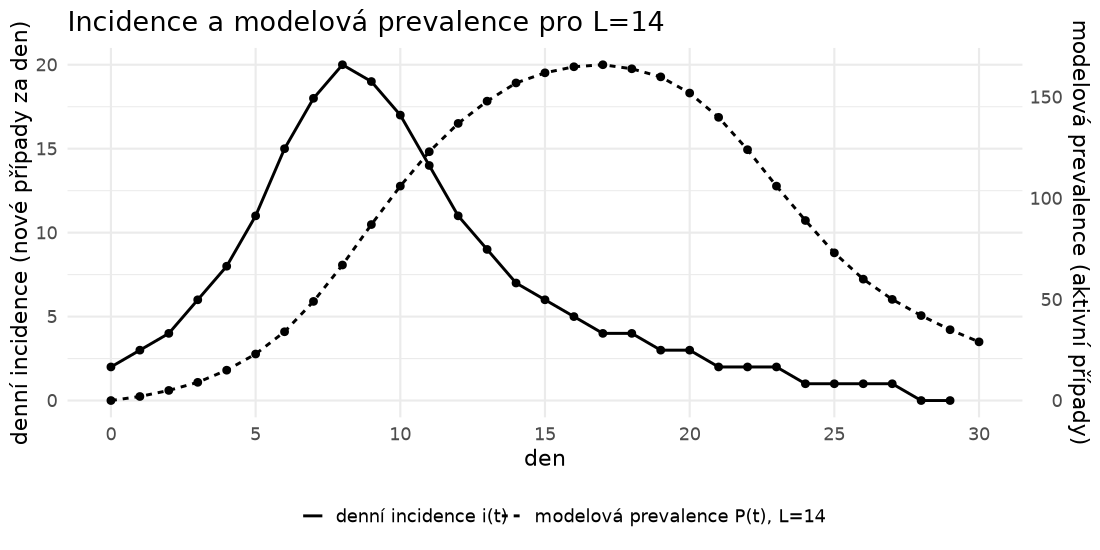

In [8]:
# Incidence a modelová prevalence mají odlišné měřítko,
# proto je zobrazíme pomocí dvou os y.
scale_factor_P <- max(P) / max(i)

plot_data_P <- rbind(
  data.frame(
    t = days,
    value = i,
    rada = "denní incidence i(t)"
  ),
  data.frame(
    t = 0:T,
    value = P / scale_factor_P,
    rada = paste0("modelová prevalence P(t), L=", L)
  )
)

ggplot(plot_data_P, aes(x = t, y = value, linetype = rada)) +
  geom_line(linewidth = 1) +
  geom_point(size = 2) +
  scale_x_continuous(
    breaks = seq(0, T, by = 5)
  ) +
  scale_y_continuous(
    name = "denní incidence (nové případy za den)",
    sec.axis = sec_axis(
      ~ . * scale_factor_P,
      name = "modelová prevalence (aktivní případy)"
    )
  ) +
  labs(
    x = "den",
    title = paste0("Incidence a modelová prevalence pro L=", L),
    linetype = NULL
  ) +
  theme_minimal(base_size = 16) +
  theme(
    legend.position = "bottom",
    panel.grid.minor.x = element_blank()
  )



### Co z příkladu plyne?

Modelová prevalence nemusí začít klesat ve stejném okamžiku jako incidence.

Z bilančního vztahu

$$
\Delta P(t)=i(t)-i(t-L)
$$

plyne:

$$
P(t)\text{ roste} \iff i(t) > i(t-L),
$$

$$
P(t)\text{ klesá} \iff i(t) < i(t-L).
$$

Nestačí tedy vědět, zda incidence právě roste nebo klesá. Rozhodující je porovnání současné incidence s incidencí před $L$ dny.

V tomto příkladu je prevalence zjednodušeně totožná s počtem aktivních případů při předpokladu pevné délky aktivity $L$.



# 3. Minibadatelský projekt: skutečná data COVID-19

Nyní použijte předchozí výsledky **samostatně na skutečných datech**.

Budeme pracovat se souborem

`covid_data_cviko.csv`

Soubor uložte **do stejné složky jako tento notebook**.

Dataset obsahuje denní údaje Ministerstva zdravotnictví ČR. Pro projekt použijte období

$$
\boxed{1.\ 10.\ 2021\;-\;20.\ 12.\ 2021}.
$$

V předchozím příkladu jsme prevalenci modelovali velmi jednoduše jako počet případů aktivních přesně $L$ dní.  
V reálných datech nyní sestavíme **evidovanou prevalenci (počet evidovaných aktivních případů)** z kumulativních údajů a porovnáme ji s tímto jednoduchým modelem.

V této části už nejsou jednotlivé kroky vyřešeny. Potřebný R kód si můžete připomenout z předchozích úloh nebo dohledat.



## 3.1 Načtení a výběr dat

1. Načtěte soubor `covid_data_cviko.csv`.
2. Prohlédněte si názvy proměnných a několik prvních řádků.
3. Zjistěte, v jakém formátu je sloupec `datum`.
4. Převeďte jej na datumový typ.
5. Vyberte období od 1. 10. 2021 do 20. 12. 2021.

### Kontrolní otázky

a) Kolik dní obsahuje vybrané období?  

b) Který sloupec odpovídá denní incidenci?  

c) Které tři kumulativní veličiny budeme později potřebovat pro výpočet evidované prevalence, tedy počtu evidovaných aktivních případů?


In [ ]:
# Vaše řešení:


## 3.2 Incidence a kumulativní počet

Vykreslete denní incidenci ve vybraném období.

Potom z incidence sami rekonstruujte kumulativní počet případů a porovnejte jej s oficiálním sloupcem `kumulativni_pocet_nakazenych`.

### Otázky

a) Kdy přibližně nastává maximum incidence?  

b) Proč samotný `cumsum` incidence nezačíná na stejné hodnotě jako oficiální kumulativní počet?  

c) Jak musíte výpočet upravit, aby obě veličiny odpovídaly?  

d) Kde se v tomto výpočtu objevuje diskrétní Newtonova–Leibnizova formule?


In [ ]:
# Vaše řešení:


## 3.3 Evidovaná prevalence

Ze zadaných kumulativních veličin vytvořte počet evidovaných aktivních případů

$$
P_{\mathrm{evid}}(t)
=
N_{\mathrm{cum}}(t)
-
R_{\mathrm{cum}}(t)
-
D_{\mathrm{cum}}(t).
$$

Tuto veličinu budeme v projektu označovat jako **evidovanou prevalenci**.

Vykreslete evidovanou prevalenci společně s denní incidencí. Protože obě veličiny mohou mít odlišné měřítko, použijte dvě osy $y$ a každou osu jasně popište:

- levá osa $y$: denní incidence,
- pravá osa $y$: evidovaná prevalence.

### Otázky

a) Nastává maximum incidence a maximum evidované prevalence ve stejný den?  

b) Pokud ne, která veličina dosáhne maxima později?  

c) Jak tento rozdíl souvisí s myšlenkou z předchozího vyřešeného příkladu?


In [ ]:
# Vaše řešení:


## 3.4 Jednoduchý model prevalence s pevnou délkou $L$

Použijte model z předchozího příkladu. Při práci s kalendářními daty budeme
$P_L(t)$ chápat jako modelovou prevalenci **na konci dne $t$**. Do
$L$-denního okna proto zahrneme i incidenci aktuálního dne:

$$
P_L(t)=\sum_{s=t-L+1}^{t}i(s).
$$

V tomto modelu předpokládáme, že každý případ zůstává aktivní přesně $L$ dní, a $P_L(t)$ proto interpretujeme jako **modelovou prevalenci**.

Vyzkoušejte alespoň

$$
L=5,\qquad L=10,\qquad L=14,\qquad L=21.
$$

V jednom grafu porovnejte:

- evidovanou prevalenci,
- modelovou prevalenci $P_5(t)$,
- modelovou prevalenci $P_{10}(t)$,
- modelovou prevalenci $P_{14}(t)$,
- modelovou prevalenci $P_{21}(t)$.

### Otázky

a) Jak se se zvětšujícím se $L$ mění výška a poloha maxima modelové prevalence?  

b) Která z vyzkoušených hodnot $L$ se podle grafu nejvíce podobá evidované prevalenci?  

c) Proč se žádná jednoduchá volba $L$ nemusí s evidovanými daty shodovat přesně?  

d) Znamenala by dobrá shoda pro určité $L$, že každý člověk zůstával aktivním případem právě $L$ dní?


In [ ]:
# Vaše řešení:


## 3.5 Závěr projektu

Odpovězte stručně vlastními slovy:

a) Jakou roli hrála v projektu **sumace**?  

b) Jakou roli hrála **diference**?  

c) Co nám umožňuje kumulativní veličina $C(t)$?  

d) Co v našem modelu představuje pohyblivý součet délky $L$?  

e) Jaký je rozdíl mezi **modelovou prevalencí** $P_L(t)$ a **evidovanou prevalencí** získanou z dat?  

f) Uveďte alespoň jeden důvod, proč je model s pevnou délkou $L$ pouze zjednodušením reality.



---

### Poznámka

Cílem projektu není vytvořit přesný epidemiologický model. Cílem je použít na skutečných datech matematické nástroje, které jsme procvičili:

$$
\text{diference} \longleftrightarrow \text{přírůstky},
$$

$$
\text{sumace} \longleftrightarrow \text{kumulace},
$$

$$
\text{pohyblivý konečný součet} \longleftrightarrow \text{modelová prevalence za posledních }L\text{ kroků}.
$$

V modelovém příkladu je prevalence ztotožněna s počtem aktivních případů při pevné délce aktivity $L$.  
V reálných datech je evidovaná prevalence určena evidovaným počtem aktivních případů a nemusí se s tímto jednoduchým modelem přesně shodovat.
